In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

In [3]:
print("TensorFlow:",tf.__version__)

TensorFlow: 2.21.0


In [4]:
TRAIN_DIR="dataset/seg_train/seg_train"
TEST_DIR="dataset/seg_test/seg_test"

IMG_SIZE=(150, 150)
BATCH_SIZE=32
SEED=42

In [5]:
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))

Training folder exists: True
Testing folder exists: True


In [6]:
class_names = sorted([
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
])

print("Number of Classes:", len(class_names))
print("Class Names:", class_names)

Number of Classes: 6
Class Names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [7]:
class_counts={}

for class_name in class_names:
    folder_path=os.path.join(TRAIN_DIR, class_name)

    images=[
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[class_name]=len(images)

df=pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

print(df)

       Class  Number of Images
0  buildings              2191
1     forest              2271
2    glacier              2404
3   mountain              2512
4        sea              2274
5     street              2382


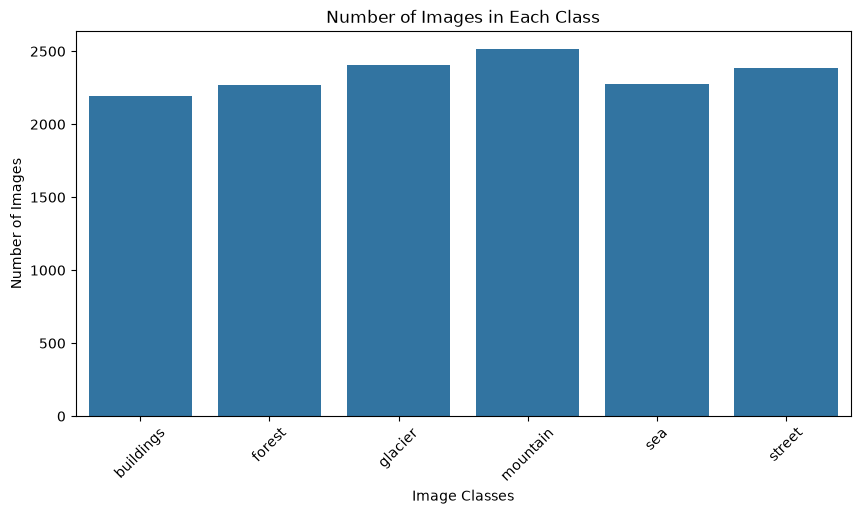

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="Class", y="Number of Images")
plt.title("Number of Images in Each Class")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

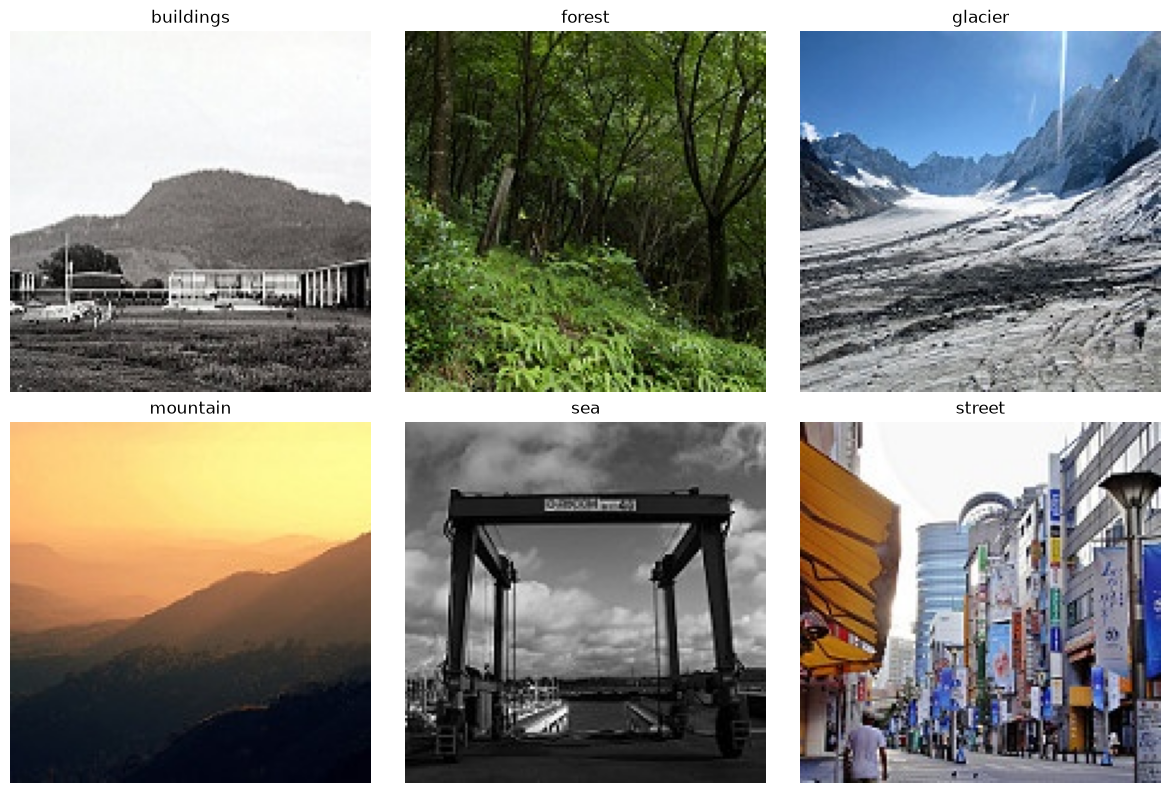

In [9]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    folder_path=os.path.join(TRAIN_DIR, class_name)
    image_files=os.listdir(folder_path)
    image_path=os.path.join(folder_path, image_files[0])
    image=keras.utils.load_img(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
train_dataset=tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

validation_dataset=tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_dataset=tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


In [11]:
print("Classes:", train_dataset.class_names)
print("Number of training batches:", len(train_dataset))
print("Number of validation batches:", len(validation_dataset))
print("Number of test batches:", len(test_dataset))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of training batches: 351
Number of validation batches: 88
Number of test batches: 94


In [12]:
normalization_layer=layers.Rescaling(1./255)

train_dataset=train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset=validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset=test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [13]:
AUTOTUNE=tf.data.AUTOTUNE

train_dataset=train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset=validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset=test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

In [14]:
data_augmentation=keras.Sequential([

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )

])

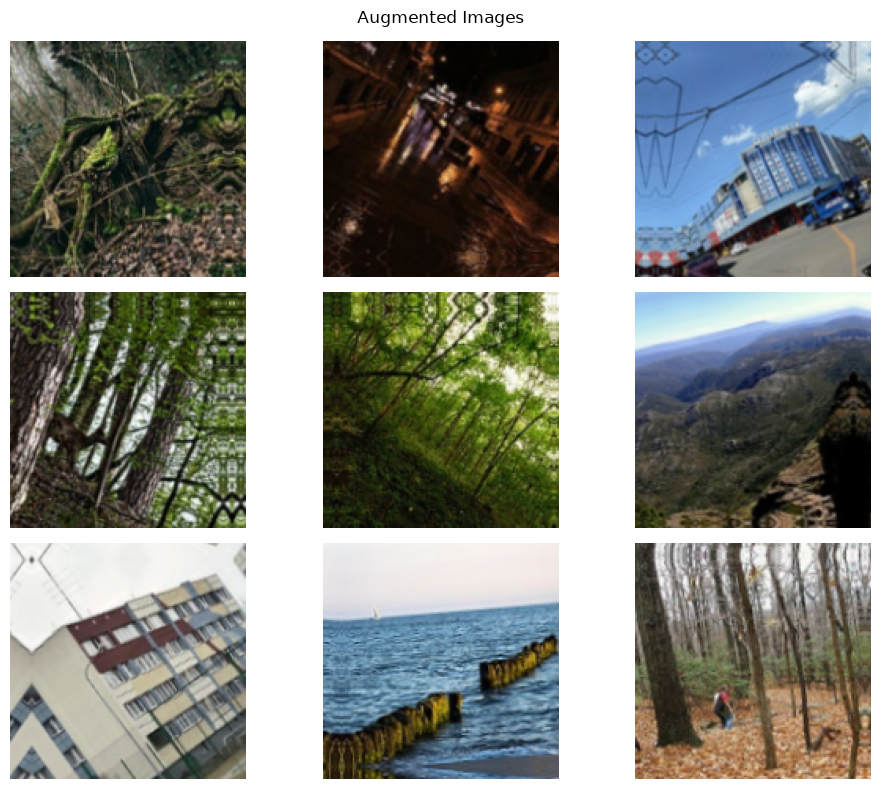

In [15]:
for images, labels in train_dataset.take(1):

    plt.figure(figsize=(10, 8))

    for i in range(9):

        augmented_image=data_augmentation(
            images[i:i+1],
            training=True
        )

        plt.subplot(3, 3, i + 1)

        plt.imshow(augmented_image[0].numpy())

        plt.axis("off")

    plt.suptitle("Augmented Images")
    plt.tight_layout()
    plt.show()

CNN model
-Input layer
-Data augmentation
-Three convolutional layers
-Three max pooling layers
-Flatten layer
-Fully connected Dense layers
-Dropout layer
-Softmax output layer

In [16]:
model=keras.Sequential([

    # Input layer
    layers.Input(shape=(150, 150, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Dropout for regularization
    layers.Dropout(0.5),

    # Output layer (6 classes)
    layers.Dense(6, activation="softmax")

])

In [17]:
model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stopping=keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True

)

model_checkpoint=keras.callbacks.ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"

)

In [20]:
history=model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]

)

Epoch 1/20


C:\Users\user\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 317s 893ms/step - accuracy: 0.5003 - loss: 1.2506 - val_accuracy: 0.6654 - val_loss: 0.9187
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 165s 468ms/step - accuracy: 0.6185 - loss: 1.0144 - val_accuracy: 0.6842 - val_loss: 0.8294
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 173s 492ms/step - accuracy: 0.6601 - loss: 0.9203 - val_accuracy: 0.7245 - val_loss: 0.7670
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 175s 498ms/step - accuracy: 0.6961 - loss: 0.8529 - val_accuracy: 0.6810 - val_loss: 0.7861
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 193s 471ms/step - accuracy: 0.7144 - loss: 0.8019 - val_accuracy: 0.7612 - val_loss: 0.6770
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 200s 465ms/step - accuracy: 0.7257 - loss: 0.7691 - val_accuracy: 0.7691 - val_loss: 0.6492
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 164s 468ms/step - accuracy: 0.7385 - loss: 0.7346 - val_accuracy: 0.7534 - val_loss: 0.6804
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 213s 499ms/step - accuracy: 0.7474 - loss: 0.70

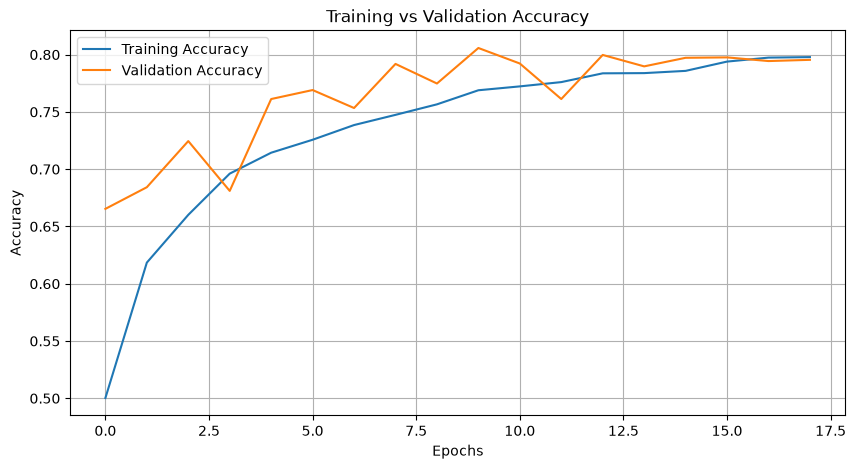

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

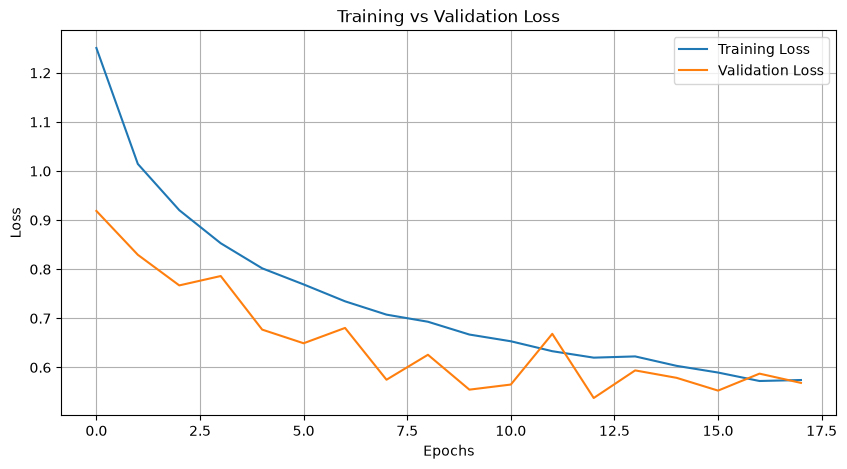

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

In [23]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

print("Test Accuracy Percentage:", test_accuracy * 100, "%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 15s 154ms/step - accuracy: 0.8017 - loss: 0.5529
Test Loss: 0.5529340505599976
Test Accuracy: 0.8016666769981384
Test Accuracy Percentage: 80.16666769981384 %


In [24]:
y_true=[]
y_pred=[]

for images, labels in test_dataset:

    predictions=model.predict(images, verbose=0)

    predicted_labels=np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())

    y_pred.extend(predicted_labels)

y_true=np.array(y_true)
y_pred=np.array(y_pred)

In [25]:
print("Classification Report")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

Classification Report
              precision    recall  f1-score   support

   buildings       0.75      0.79      0.77       437
      forest       0.96      0.93      0.95       474
     glacier       0.80      0.76      0.78       553
    mountain       0.85      0.59      0.70       525
         sea       0.69      0.88      0.77       510
      street       0.82      0.87      0.84       501

    accuracy                           0.80      3000
   macro avg       0.81      0.80      0.80      3000
weighted avg       0.81      0.80      0.80      3000



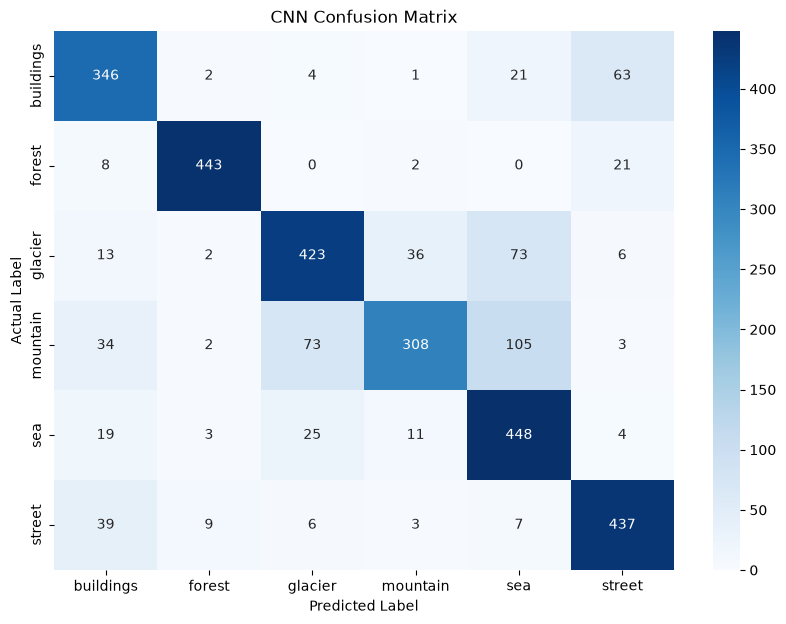

In [26]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.show()

In [30]:
# Get all test image paths
test_file_paths = []

for class_name in class_names:

    folder_path = os.path.join(TEST_DIR, class_name)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            test_file_paths.append(
                os.path.join(folder_path, filename)
            )

print("Total test images:", len(test_file_paths))

Total test images: 3000


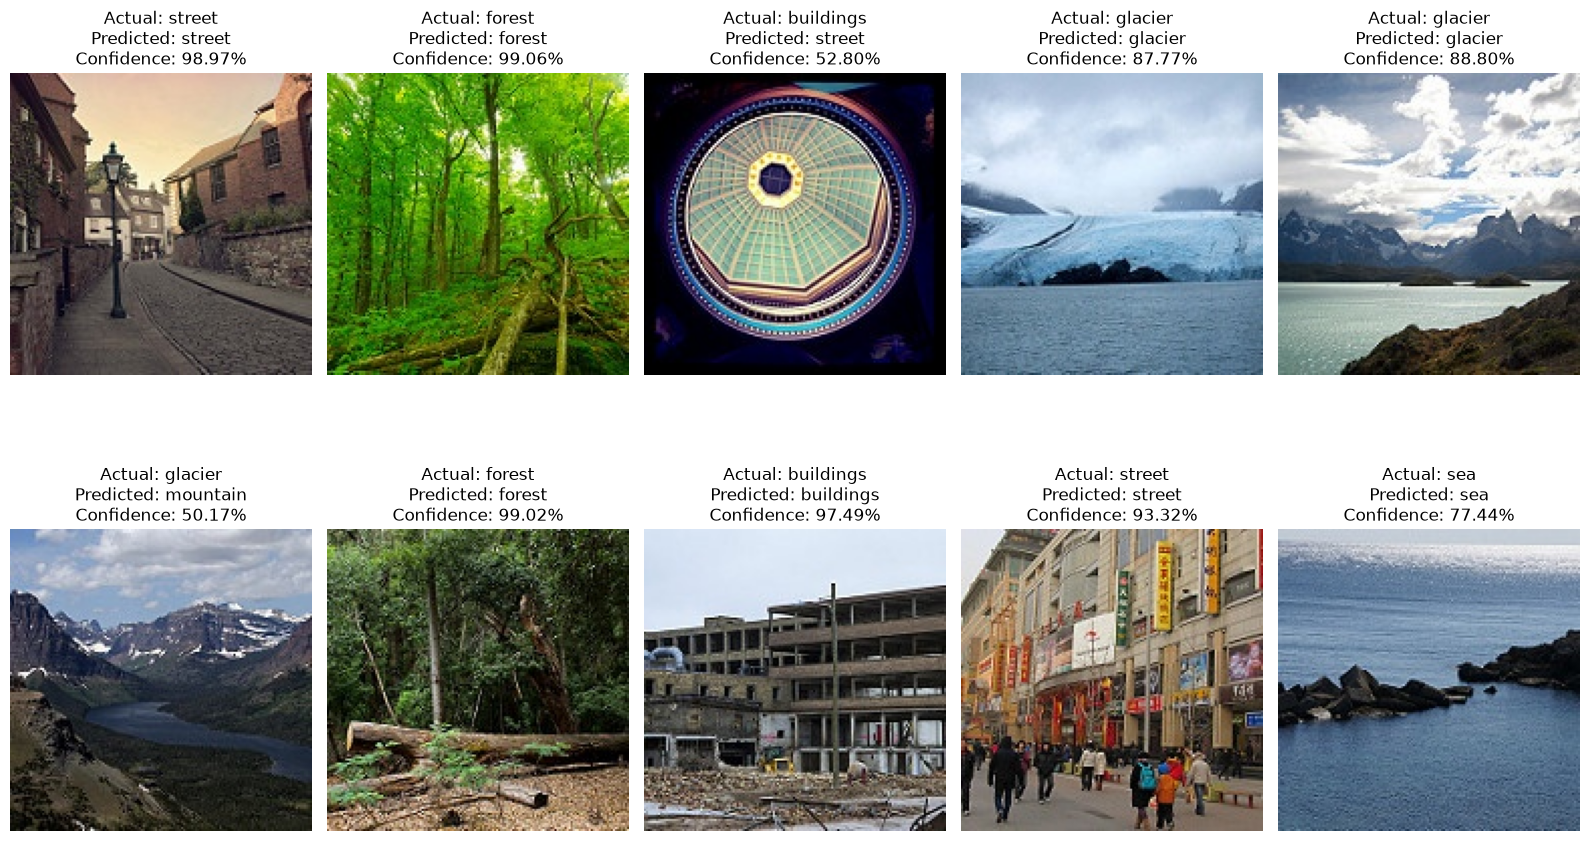

In [31]:
random.seed(42)

random_images = random.sample(test_file_paths, 10)

plt.figure(figsize=(16, 10))

for i, image_path in enumerate(random_images):

    # Load image
    image = keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    # Convert image to array
    image_array = keras.utils.img_to_array(image)

    # Normalize
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    prediction = model.predict(image_array, verbose=0)

    predicted_class = np.argmax(prediction)

    predicted_class_name = class_names[predicted_class]

    # Actual label
    actual_class = os.path.basename(
        os.path.dirname(image_path)
    )

    # Confidence
    confidence = np.max(prediction) * 100

    # Display image
    plt.subplot(2, 5, i + 1)

    plt.imshow(image)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class_name}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
model.save("intel_image_classification_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [33]:
import json

with open("class_names.json", "w") as file:

    json.dump(class_names, file)

print("Class names saved successfully!")

Class names saved successfully!


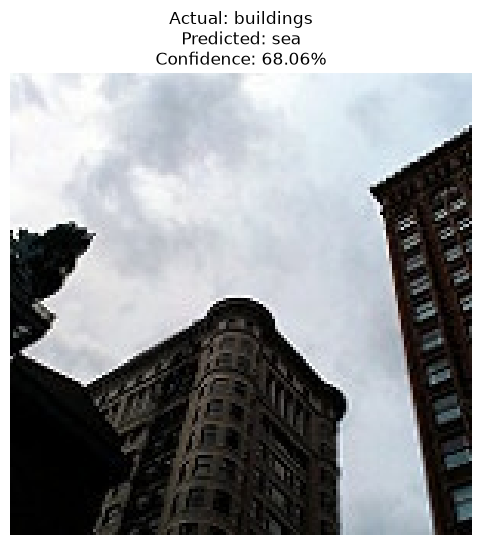

In [35]:
# Select a random image from test dataset
image_path = random.choice(test_file_paths)

# Load image
image = keras.utils.load_img(
    image_path,
    target_size=IMG_SIZE
)

# Convert to array
image_array = keras.utils.img_to_array(image)

# Normalize
image_array = image_array / 255.0

# Add batch dimension
image_array = np.expand_dims(image_array, axis=0)

# Predict
prediction = model.predict(image_array, verbose=0)

predicted_class = np.argmax(prediction)

# Get actual and predicted labels
actual_class = os.path.basename(
    os.path.dirname(image_path)
)

predicted_class_name = class_names[predicted_class]

confidence = np.max(prediction) * 100

# Display result
plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class_name}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

## Conclusion:

The CNN model was successfully developed using TensorFlow and Keras for the Intel Image Classification Dataset. The dataset contained six different categories: Buildings, Forest, Glacier, Mountain, Sea and Street.

The images were resized to 150 × 150 pixels and normalized. Data augmentation techniques such as rotation, flipping, zooming and translation were applied to improve model generalization.

A CNN architecture was developed using three convolutional layers, max pooling, fully connected layers and dropout. The model was trained using the Adam optimizer and sparse categorical crossentropy loss function. Early stopping and model checkpointing were also implemented.

The model was evaluated using test accuracy, precision, recall, F1-score and a confusion matrix. Finally, predictions were visualized on ten randomly selected test images.

The experiment demonstrates how CNNs can automatically extract image features and perform multi-class image classification.